## What a classifier does

`make_moons` creates an **invented** dataset for practice. Each of the 500 points has a **position** (`x1`, `x2`, the features X) and a **class** (`0` = upper moon, `1` = lower moon, the label y). The classifier learns to guess the class from the position.

| | Regression | Classification |
|---|---|---|
| Example | California, salaries | Moons, iris |
| Predicts | A number (price, salary) | A class (0 or 1) |
| `score` gives | R² | **Accuracy** (fraction of correct answers) |

The process is the same as always:
1. **`fit`** on the training points: the model sees positions **and** classes, and learns a rule.
2. **`predict`** on the test points: it only sees positions, and guesses the class.
3. **`score`** compares the guesses with the real classes: 0.9 means 90% correct.

**A classification tree** makes the same splits as in regression (`x1 < 0.4?`, `x2 > 0.2?`...), but each leaf holds the **most common class** of its points (a vote) instead of the average. The splits divide the plane into zones painted 0 or 1. The line between the zones is the **decision boundary**.

**Why moons?** With only 2 features we can **see** the points and the zones the model paints. The moons interlock, so a straight line can't separate them, and the noise mixes some points:
- **one tree** follows every noisy point and paints little islands (overfitting);
- **a forest** averages many trees and paints a smoother boundary, which should score better on test.

Real-world version: `x1` = age, `x2` = income, class = bought the product (1) or not (0).

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_moons, y_moons = make_moons(n_samples=500, noise=0.3, random_state=42)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=42
)

tree_classifier = DecisionTreeClassifier(random_state=42).fit(
    X_moons_train, y_moons_train
)

forest_classifier = RandomForestClassifier(random_state=42).fit(
    X_moons_train, y_moons_train
)

{
    "tree": tree_classifier.score(X_moons_test, y_moons_test),
    "forest": forest_classifier.score(X_moons_test, y_moons_test),
}

{'tree': 0.8533333333333334, 'forest': 0.9066666666666666}

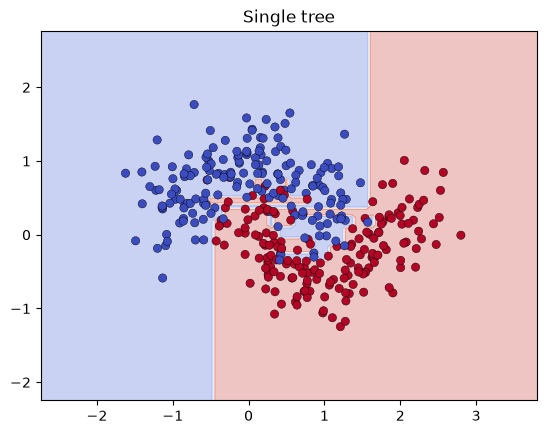

In [6]:
from sklearn.inspection import DecisionBoundaryDisplay


def plot_boundary(classifier, title):
    DecisionBoundaryDisplay.from_estimator(
        classifier, X_moons, response_method="predict_proba", alpha=0.3, cmap="coolwarm"
    )
    plt.scatter(
        X_moons_train[:, 0],
        X_moons_train[:, 1],
        c=y_moons_train,
        cmap="coolwarm",
        edgecolors="k",
        linewidth=0.3,
    )
    plt.title(title)
    plt.show()


plot_boundary(tree_classifier, "Single tree")

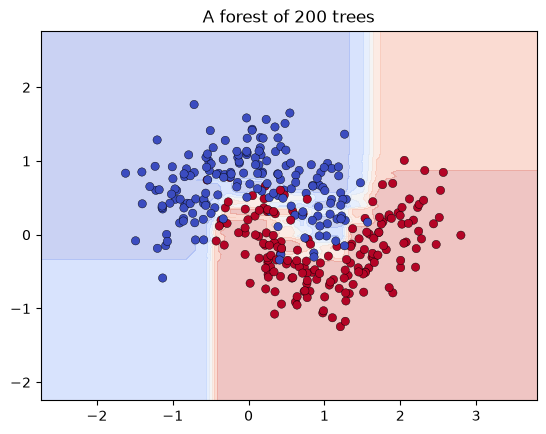

In [7]:
plot_boundary(forest_classifier, 'A forest of 200 trees')